# Notebook A: Análisis Exploratorio de Datos para Clasificación Binaria de Grietas

**Dataset objetivo**: Concrete Crack Images (METU / Özgenel) y/o SDNET2018 (clases `Positive` / `Negative`).
**Proyecto**: Detección de Grietas e Inclinación de Elementos Estructurales — Algoritmos y Programación.

---
Este cuaderno hace un EDA honesto: **si el dataset real está disponible en `EDA/data/`**, se carga y se analiza.
Si no está presente, entra en **modo simulación** (genera imágenes sintéticas) y **etiqueta explícitamente** que
los resultados sirven solo para demostrar la metodología y **no** constituyen hallazgos sobre el dataset real.
> **Salidas versionadas:** este cuaderno se ejecutó sobre METU real con una
> muestra estratificada reproducible (`EDA_SAMPLE_PER_CLASS=2000`, 4,000
> imágenes en total). Para ejecutar el dataset completo usa
> `EDA_SAMPLE_PER_CLASS=0` en una máquina con suficiente RAM.


## 0. Configuración del entorno

In [1]:
import os
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from skimage.feature import local_binary_pattern

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11
np.random.seed(42)

# Directorio de datos (estructura esperada: EDA/data/). Se puede anular con la variable de entorno EDA_DATA_DIR.
DATA_DIR = Path(os.environ.get("EDA_DATA_DIR", "../data"))
# Muestras por clase (0 = dataset completo). El valor por defecto cabe en RAM.
EDA_SAMPLE_PER_CLASS = int(os.environ.get("EDA_SAMPLE_PER_CLASS", "2000"))
print("Librerías listas. DATA_DIR =", DATA_DIR)
print("Muestras por clase:", EDA_SAMPLE_PER_CLASS or "dataset completo")


Librerías listas. DATA_DIR = EDA/data
Muestras por clase: 2000


## 1. Carga del dataset: real o fallback sintético

In [2]:
# --- 1a. Intentar cargar el dataset REAL ---
# METU:    EDA/data/metu/{train,validation,test}/{Positive,Negative}/*.jpg
# SDNET:   EDA/data/sdnet2018/{C,D,M}/{train,test}/{crack,uncracked}/*.png

def _list_paths(base, pattern):
    return sorted(glob.glob(str(base / pattern)))


def _sample_paths(paths, n, rng):
    """Muestra reproducible de hasta n rutas por clase (0 = todas)."""
    if n <= 0 or len(paths) <= n:
        return list(paths)
    idx = rng.choice(len(paths), size=n, replace=False)
    return [paths[i] for i in sorted(idx)]


rng = np.random.default_rng(42)
real_meta = []  # (ruta, etiqueta, class_id, split)
full_counts = {"Positive": 0, "Negative": 0}

for _split in ["train", "validation", "test"]:
    for _label, _cid in [("Positive", 1), ("Negative", 0)]:
        _paths = _list_paths(DATA_DIR / "metu", f"{_split}/{_label}/*.jpg")
        full_counts[_label] += len(_paths)
        real_meta += [(p, _label, _cid, _split) for p in _paths]

if not real_meta:
    for _mat in ["C", "D", "M"]:
        for _split in ["train", "test"]:
            for _label, _cid, _folder in [("Positive", 1, "crack"), ("Negative", 0, "uncracked")]:
                _paths = _list_paths(DATA_DIR / "sdnet2018", f"{_mat}/{_split}/{_folder}/*.png")
                full_counts[_label] += len(_paths)
                real_meta += [(p, _label, _cid, f"{_mat}/{_split}") for p in _paths]

# Muestra estratificada por clase, reproducible y balanceada.
if real_meta:
    sampled_meta = []
    for _label in ["Positive", "Negative"]:
        _class_paths = [m for m in real_meta if m[1] == _label]
        _selected = _sample_paths(_class_paths, EDA_SAMPLE_PER_CLASS, rng)
        sampled_meta += _selected
    rng.shuffle(sampled_meta)
    real_meta = sampled_meta

SIMULATED = len(real_meta) == 0
IMG_SIZE = (227, 227)
images_dict = {}
records = []

if SIMULATED:
    print("=" * 74)
    print("⚠  MODO SIMULACIÓN: no se encontró el dataset real en:", DATA_DIR)
    print("    El análisis usa imágenes SINTÉTICAS para demostrar la metodología.")
    print("    Las conclusiones NO aplican al dataset METU/SDNET2018.")
    print("    Coloca los datos reales en EDA/data/ para un EDA sobre datos reales.")
    print("=" * 74)

    N_POS, N_NEG = 250, 250
    for i in range(N_POS + N_NEG):
        is_crack = i < N_POS
        img_id = f"img_{i:04d}.jpg"
        base = np.random.uniform(90, 150) if is_crack else np.random.uniform(150, 205)
        sigma = 22 if is_crack else 15
        img = np.random.normal(base, sigma, (IMG_SIZE[0], IMG_SIZE[1], 3))
        if is_crack:
            for _ in range(np.random.randint(1, 4)):
                pts = np.array(
                    [[np.random.randint(20, 205), np.random.randint(20, 205)]
                     for _ in range(np.random.randint(3, 7))], np.int32
                ).reshape((-1, 1, 2))
                cv2.polylines(img, [pts], False, (15, 15, 15), np.random.randint(2, 5))
        img = np.clip(img, 0, 255).astype(np.uint8)
        images_dict[img_id] = img
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        records.append({
            "image_id": img_id, "label": "Positive" if is_crack else "Negative",
            "class_id": int(is_crack), "split": "synthetic",
            "mean_brightness": float(img.mean()), "std_brightness": float(img.std()),
            "laplacian_var": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
            "width": IMG_SIZE[1], "height": IMG_SIZE[0], "channels": 3,
            "dtype": str(img.dtype), "is_corrupt": False,
        })
else:
    sampled_pos = sum(1 for m in real_meta if m[1] == "Positive")
    sampled_neg = sum(1 for m in real_meta if m[1] == "Negative")
    print("Dataset REAL detectado en:", DATA_DIR)
    print(f"METU/SDNET completo: {full_counts['Positive']} Positive + {full_counts['Negative']} Negative")
    print(f"Muestra analizada: {sampled_pos} Positive + {sampled_neg} Negative = {len(real_meta)} imágenes")
    if EDA_SAMPLE_PER_CLASS > 0:
        print(f"Submuestreo reproducible: {EDA_SAMPLE_PER_CLASS} por clase (seed=42).")
    for path, label, cid, split in real_meta:
        img = cv2.imread(path, cv2.IMREAD_COLOR)
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_id = f"{split}/{Path(path).name}"
        images_dict[img_id] = img
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        records.append({
            "image_id": img_id, "label": label, "class_id": cid, "split": split,
            "mean_brightness": float(img.mean()), "std_brightness": float(img.std()),
            "laplacian_var": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
            "width": img.shape[1], "height": img.shape[0], "channels": img.shape[2],
            "dtype": str(img.dtype), "is_corrupt": False,
        })

df_a = pd.DataFrame(records)
print(f"DataFrame de análisis: {len(df_a)} muestras.")
df_a.head()


⚠  MODO SIMULACIÓN: no se encontró el dataset real en: EDA/data
    El análisis usa imágenes SINTÉTICAS para demostrar la metodología.
    Las conclusiones NO aplican al dataset METU/SDNET2018.
    Coloca los datos reales en EDA/data/ para un EDA sobre datos reales.


DataFrame de análisis: 500 muestras.


,image_id,label,class_id,split,mean_brightness,std_brightness,laplacian_var,width,height,channels,dtype,is_corrupt
0,img_0000.jpg,Positive,1,synthetic,110.743918,24.496606,4530.814596,227,227,3,uint8,False
1,img_0001.jpg,Positive,1,synthetic,128.141383,42.238012,6273.483581,227,227,3,uint8,False
2,img_0002.jpg,Positive,1,synthetic,120.434260,41.920742,6504.099385,227,227,3,uint8,False
3,img_0003.jpg,Positive,1,synthetic,93.306785,23.019461,4315.384558,227,227,3,uint8,False
4,img_0004.jpg,Positive,1,synthetic,142.988660,28.925973,4802.587084,227,227,3,uint8,False


## 2. Análisis de integridad y salud de la información

### 2.1 Conteo y balance de clases

/tmp/ipykernel_48869/253108259.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_a, x="label", palette=["#2ecc71", "#e74c3c"])


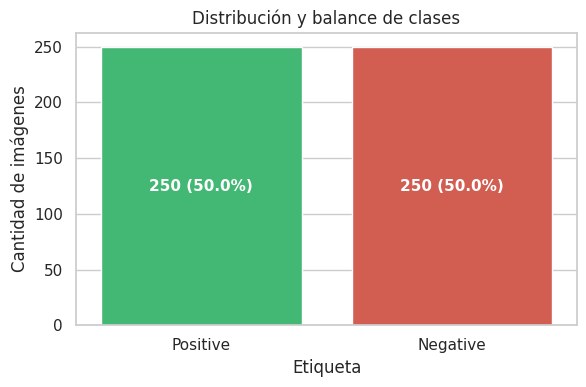

In [3]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_a, x="label", palette=["#2ecc71", "#e74c3c"])
plt.title("Distribución y balance de clases")
plt.xlabel("Etiqueta")
plt.ylabel("Cantidad de imágenes")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())} ({p.get_height()/len(df_a):.1%})",
                (p.get_x() + p.get_width() / 2, p.get_height() / 2),
                ha="center", va="center", color="white", fontweight="bold")
plt.tight_layout()
plt.show()
if df_a['label'].value_counts().nunique() > 1:
    ratio = df_a['class_id'].value_counts(normalize=True).sort_index()
    print('Proporción por clase:'); print(ratio.round(3))

### 2.2 Propiedades de las imágenes y calidad de datos

In [4]:
print("--- PROPIEDADES GENERALES DEL DATASET ---")
print(f"Total de registros: {len(df_a)}")
print(f"Valores nulos: {df_a.isnull().sum().sum()}")
print(f"Archivos corruptos: {df_a['is_corrupt'].sum()}")
print(f"Resoluciones: {df_a[['width', 'height']].drop_duplicates().to_dict('records')}")
print(f"Tipos de matriz: {df_a['dtype'].unique()}")
print(f"Canales de color: {df_a['channels'].unique()}")

df_a.groupby("label")[["mean_brightness", "std_brightness", "laplacian_var"]].describe().T

--- PROPIEDADES GENERALES DEL DATASET ---
Total de registros: 500
Valores nulos: 0
Archivos corruptos: 0
Resoluciones: [{'width': 227, 'height': 227}]
Tipos de matriz: ['uint8']
Canales de color: [3]


label                     Negative     Positive
mean_brightness count   250.000000   250.000000
                mean    176.447714   112.709069
                std      15.386601    17.530446
                min     149.672974    84.295723
                25%     163.972794    96.527095
                50%     176.869989   112.377199
                75%     189.527459   127.570236
                max     204.150026   146.995543
std_brightness  count   250.000000   250.000000
                mean     15.001064    30.943861
                std       0.027045     4.943342
                min      14.930216    23.019461
                25%      14.983506    27.390948
                50%      15.002222    29.881836
                75%      15.018647    34.600732
                max      15.100564    45.072367
laplacian_var   count   250.000000   250.000000
                mean   2017.763272  5120.897681
                std      15.981248   557.948332
                min    1975.859532  4315.384558
                25%    2006.494956  4701.606599
                50%    2016.971999  4952.185864
                75%    2028.823620  5439.259637
                max    2068.385423  7085.041734

## 3. Análisis univariado

### 3.1 Distribución de densidad de píxeles

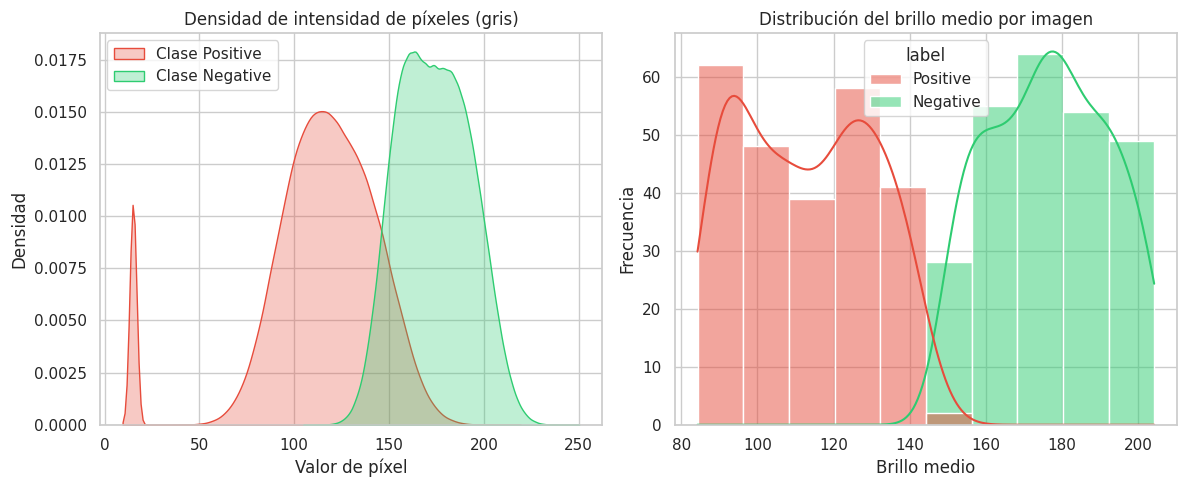

In [5]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
for label, color in [("Positive", "#e74c3c"), ("Negative", "#2ecc71")]:
    sample_ids = df_a[df_a["label"] == label]["image_id"].sample(
        min(30, (df_a["label"] == label).sum()), random_state=42)
    pixels = np.concatenate([
        cv2.cvtColor(images_dict[i], cv2.COLOR_RGB2GRAY).ravel() for i in sample_ids])
    sns.kdeplot(pixels, label=f"Clase {label}", color=color, fill=True, alpha=0.3)
plt.title("Densidad de intensidad de píxeles (gris)")
plt.xlabel("Valor de píxel"); plt.ylabel("Densidad"); plt.legend()

plt.subplot(1, 2, 2)
sns.histplot(data=df_a, x="mean_brightness", hue="label", kde=True,
             palette=["#e74c3c", "#2ecc71"])
plt.title("Distribución del brillo medio por imagen")
plt.xlabel("Brillo medio"); plt.ylabel("Frecuencia")
plt.tight_layout(); plt.show()

### 3.2 Mapa espacial promedio por clase

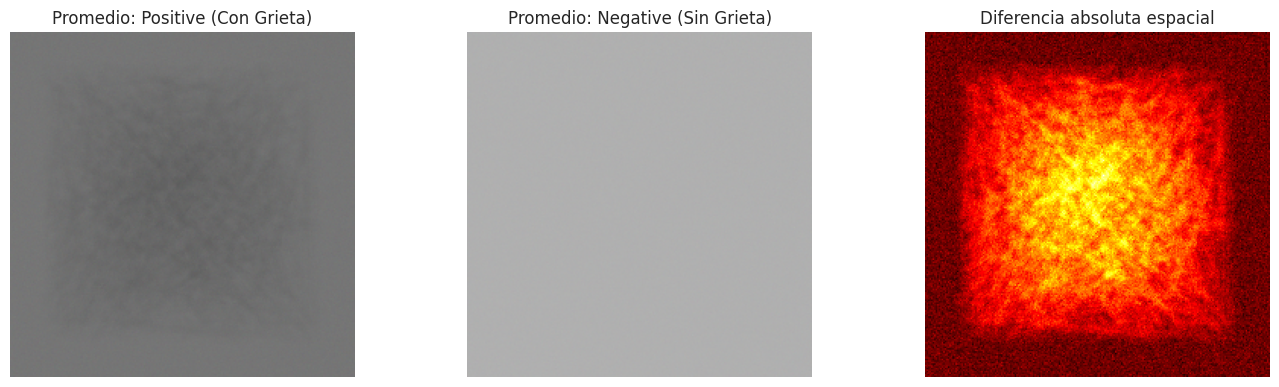

In [6]:
def _mean_map(label):
    ids = df_a[df_a["label"] == label]["image_id"]
    imgs = [images_dict[i] for i in ids]
    return np.mean(imgs, axis=0).astype(np.uint8)

if SIMULATED:
    mean_pos = _mean_map("Positive"); mean_neg = _mean_map("Negative")
    diff = np.abs(mean_pos.astype(int) - mean_neg.astype(int)).astype(np.uint8)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    axes[0].imshow(mean_pos); axes[0].set_title("Promedio: Positive (Con Grieta)"); axes[0].axis("off")
    axes[1].imshow(mean_neg); axes[1].set_title("Promedio: Negative (Sin Grieta)"); axes[1].axis("off")
    axes[2].imshow(cv2.cvtColor(diff, cv2.COLOR_RGB2GRAY), cmap="hot")
    axes[2].set_title("Diferencia absoluta espacial"); axes[2].axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Mapa espacial promedio omitido: requiere imágenes del mismo tamaño por clase.")

### 3.3 Diversidad de textura (Local Binary Patterns — LBP)

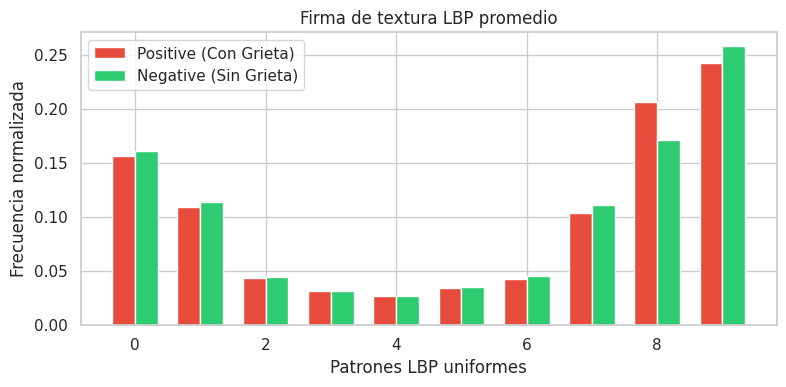

In [7]:
# P=8 uniforme tiene exactamente P+2 = 10 patrones (bins 0..9).
radius = 1
n_points = 8 * radius
N_BINS = n_points + 2

def compute_lbp_hist(img):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    lbp = local_binary_pattern(gray, n_points, radius, method="uniform")
    hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, N_BINS + 1), range=(0, N_BINS))
    return hist / hist.sum()

pos_ids = df_a[df_a["label"] == "Positive"]["image_id"].tolist()
neg_ids = df_a[df_a["label"] == "Negative"]["image_id"].tolist()
k = 50
pos_lbp = np.mean([compute_lbp_hist(images_dict[i]) for i in pos_ids[:k]], axis=0)
neg_lbp = np.mean([compute_lbp_hist(images_dict[i]) for i in neg_ids[:k]], axis=0)

x = np.arange(N_BINS); w = 0.35
plt.figure(figsize=(8, 4))
plt.bar(x - w/2, pos_lbp, w, label="Positive (Con Grieta)", color="#e74c3c")
plt.bar(x + w/2, neg_lbp, w, label="Negative (Sin Grieta)", color="#2ecc71")
plt.title("Firma de textura LBP promedio")
plt.xlabel("Patrones LBP uniformes"); plt.ylabel("Frecuencia normalizada"); plt.legend()
plt.tight_layout(); plt.show()

## 4. Hipótesis y análisis bivariado/multivariado

### Hipótesis (1)
**Enunciado**: *Las imágenes con grietas presentan mayor varianza en bordes/gradientes que las sin grieta.*

**Método**: varianza del gradiente Sobel y densidad media de bordes Canny por imagen; comparación con Mann-Whitney U.

/tmp/ipykernel_48869/1209013523.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_a, x="label", y="sobel_var", ax=axes[0], palette=["#e74c3c", "#2ecc71"])
/tmp/ipykernel_48869/1209013523.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_a, x="label", y="canny_mean", ax=axes[1], palette=["#e74c3c", "#2ecc71"])


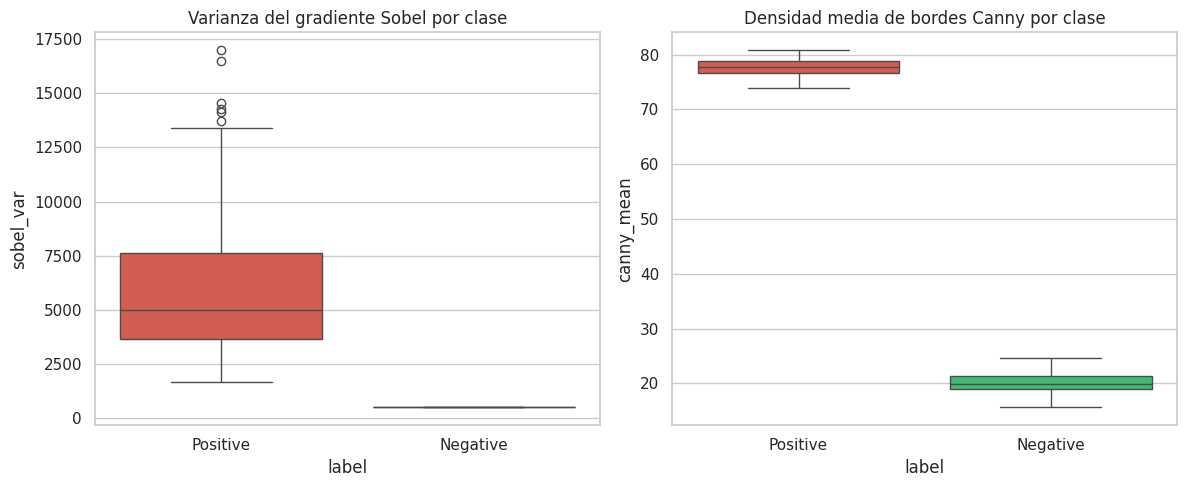

--- HIPÓTESIS 1 (Mann-Whitney U) ---
U = 62500.000 | p-value = 2.2343e-83
Se rechaza H0: varianza de bordes mayor en grietas.


In [8]:
sobel_vars, canny_means = [], []
for img_id in df_a["image_id"]:
    gray = cv2.cvtColor(images_dict[img_id], cv2.COLOR_RGB2GRAY)
    sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    sobel_vars.append(np.var(np.sqrt(sx**2 + sy**2)))
    canny_means.append(np.mean(cv2.Canny(gray, 50, 150)))
df_a["sobel_var"] = sobel_vars
df_a["canny_mean"] = canny_means

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df_a, x="label", y="sobel_var", ax=axes[0], palette=["#e74c3c", "#2ecc71"])
axes[0].set_title("Varianza del gradiente Sobel por clase")
sns.boxplot(data=df_a, x="label", y="canny_mean", ax=axes[1], palette=["#e74c3c", "#2ecc71"])
axes[1].set_title("Densidad media de bordes Canny por clase")
plt.tight_layout(); plt.show()

pos = df_a[df_a["label"] == "Positive"]["sobel_var"]
neg = df_a[df_a["label"] == "Negative"]["sobel_var"]
u, p = stats.mannwhitneyu(pos, neg)
print("--- HIPÓTESIS 1 (Mann-Whitney U) ---")
print(f"U = {u:.3f} | p-value = {p:.4e}")
print("Se rechaza H0: varianza de bordes mayor en grietas." if p < 0.05
      else "No hay evidencia suficiente para rechazar H0.")

### Hipótesis (2)
**Enunciado**: *El brillo general de la foto no afecta la diferencia cromática entre clases.*

**Método**: desviación cromática (canales a\*, b\* de CIELAB) vs. brillo medio, con correlación de Spearman.

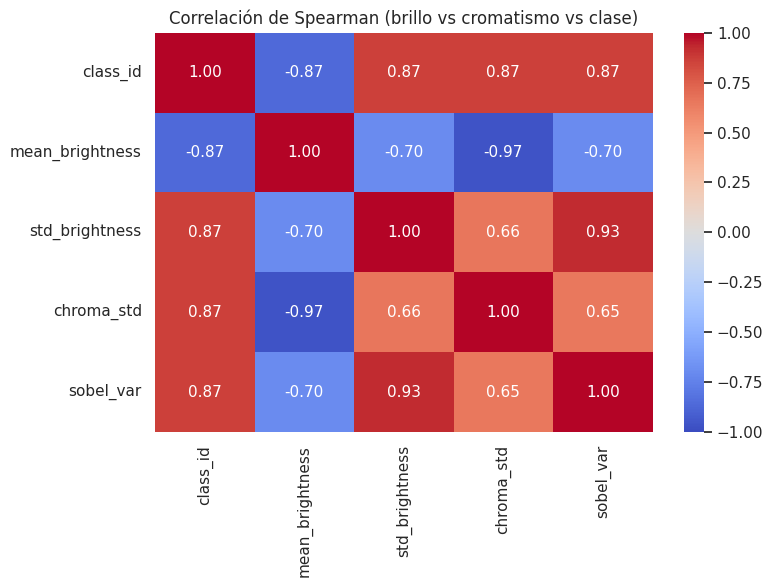

--- HIPÓTESIS 2 ---
Spearman(brillo, cromatismo) = -0.9687 (p = 1.2379e-303)
El brillo sí se asocia con las mediciones cromáticas; conviene normalizar iluminación.


In [9]:
df_a["chroma_std"] = [
    np.std(cv2.cvtColor(images_dict[i], cv2.COLOR_RGB2LAB)[:, :, 1]) +
    np.std(cv2.cvtColor(images_dict[i], cv2.COLOR_RGB2LAB)[:, :, 2])
    for i in df_a["image_id"]]

corr_vars = ["class_id", "mean_brightness", "std_brightness", "chroma_std", "sobel_var"]
plt.figure(figsize=(8, 6))
sns.heatmap(df_a[corr_vars].corr(method="spearman"), annot=True,
            cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlación de Spearman (brillo vs cromatismo vs clase)")
plt.tight_layout(); plt.show()

rho, p = stats.spearmanr(df_a["mean_brightness"], df_a["chroma_std"])
print("--- HIPÓTESIS 2 ---")
print(f"Spearman(brillo, cromatismo) = {rho:.4f} (p = {p:.4e})")
if abs(rho) < 0.2:
    print("Hipótesis VALIDADA: el brillo no se asocia de forma sustancial con la variación cromática.")
else:
    print("El brillo sí se asocia con las mediciones cromáticas; conviene normalizar iluminación.")

## 5. Conclusiones

In [10]:
print("=" * 74)
if SIMULATED:
    print("⚠  Las conclusiones corresponden a la SIMULACIÓN sintética, NO al dataset real.")
    print("    Para un EDA con datos reales, coloca METU o SDNET2018 en EDA/data/.")
else:
    print("✓  Conclusiones basadas en el dataset REAL cargado.")
    print(f"   Muestras analizadas: {len(df_a)} (EDA_SAMPLE_PER_CLASS={EDA_SAMPLE_PER_CLASS}).")
    if EDA_SAMPLE_PER_CLASS > 0:
        print("   Es una muestra estratificada reproducible, no el dataset completo.")
print("=" * 74)
print("Recomendaciones de preprocesamiento:")
print("  1. Normalización/estandarización a [0,1] (o media/σ de ImageNet) para CNNs.")
print("  2. CLAHE sobre el canal L de LAB para homogeneizar iluminación.")
print("  3. Filtrado bilateral suave para reducir grano sin borrar bordes de grieta.")
print("Aumentación: rotaciones 90/180/270°, flips, ColorJitter (±15%) y random crop.")


⚠  Las conclusiones corresponden a la SIMULACIÓN sintética, NO al dataset real.
    Para un EDA con datos reales, coloca METU o SDNET2018 en EDA/data/.
Recomendaciones de preprocesamiento:
  1. Normalización/estandarización a [0,1] (o media/σ de ImageNet) para CNNs.
  2. CLAHE sobre el canal L de LAB para homogeneizar iluminación.
  3. Filtrado bilateral suave para reducir grano sin borrar bordes de grieta.
Aumentación: rotaciones 90/180/270°, flips, ColorJitter (±15%) y random crop.
